#1. What is Naive Bayes?
Naive Bayes is a Supervised Machine Learning algorithm mainly used for classification.

It is based on Bayes' Theorem and uses probability to predict which category a data point belongs to.
Simple example
Imagine an email classification system.

It receives an email:

"Congratulations! You won a free prize."

Naive Bayes checks the words and calculates the probability of the email being:
- Spam
- Not Spam
It predicts whichever category has the higher probability.

#2. Bayes' Theorem
This is the mathematical foundation of Naive Bayes.

[
P(A|B)={P(B|A)\times P(A)}/{P(B)}
]

###Where:
Term	Meaning

P(A)	Prior probability

P(B)	Evidence probability

P(A|B)	Posterior probability

P(B|A)	Likelihood

###Simple meaning: Given some evidence, how likely is a particular event?
###Why is it called Naive Bayes?
###It makes a simplifying assumption that features are conditionally independent given the class.

###For example, in email classification, it treats each word as independent of the others once the email's category is known.

###This assumption is often not perfectly true, but the algorithm can still perform well.

#4. Today's Practical Plan
We'll use the Breast Cancer Wisconsin dataset again so we can compare Naive Bayes performance with our previous SVM models.
1. Load the dataset.
2. Separate features and target.
3. Perform train-test split.
4. Train Gaussian Naive Bayes.
5. Make predictions.
6. Evaluate Accuracy, Precision, Recall and F1-score.
7. Generate a confusion matrix.
8. Compare Naive Bayes with SVM.

#5. Practical — Code Cell 1
First, import the required libraries and load the dataset.

Code Cell 1 — Load Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

# Load Breast Cancer dataset
cancer = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df["Diagnosis"] = cancer.target

print("Dataset Loaded Successfully!")

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nTarget Classes:")
print(cancer.target_names)

Dataset Loaded Successfully!

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  w

In [2]:
# Separate features and target

X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Distribution in Percentage:")
print(y.value_counts(normalize=True) * 100)

Features Shape: (569, 30)
Target Shape: (569,)

Target Distribution:
Diagnosis
1    357
0    212
Name: count, dtype: int64

Target Distribution in Percentage:
Diagnosis
1    62.741652
0    37.258348
Name: proportion, dtype: float64


In [3]:
from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Features: (455, 30)
Testing Features: (114, 30)

Training Target: (455,)
Testing Target: (114,)

Training Class Distribution:
Diagnosis
1    285
0    170
Name: count, dtype: int64

Testing Class Distribution:
Diagnosis
1    72
0    42
Name: count, dtype: int64


In [4]:
from sklearn.naive_bayes import GaussianNB

# Create Gaussian Naive Bayes model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train, y_train)

print("Gaussian Naive Bayes Model Trained Successfully!")

print("\nModel:", nb_model)

Gaussian Naive Bayes Model Trained Successfully!

Model: GaussianNB()


In [5]:
# Make predictions
y_pred = nb_model.predict(X_test)

# Display first 10 predictions
results = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})

print("First 10 Predictions:")
print(results)

print("\nTotal Predictions:", len(y_pred))

First 10 Predictions:
   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          0
5       1          1
6       1          1
7       0          0
8       0          0
9       0          0

Total Predictions: 114


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Naive Bayes Model Evaluation")
print("-----------------------------")

print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score:  {f1:.4f} ({f1*100:.2f}%)")

Naive Bayes Model Evaluation
-----------------------------
Accuracy:  0.9386 (93.86%)
Precision: 0.9452 (94.52%)
Recall:    0.9583 (95.83%)
F1 Score:  0.9517 (95.17%)


Confusion Matrix:
[[38  4]
 [ 3 69]]


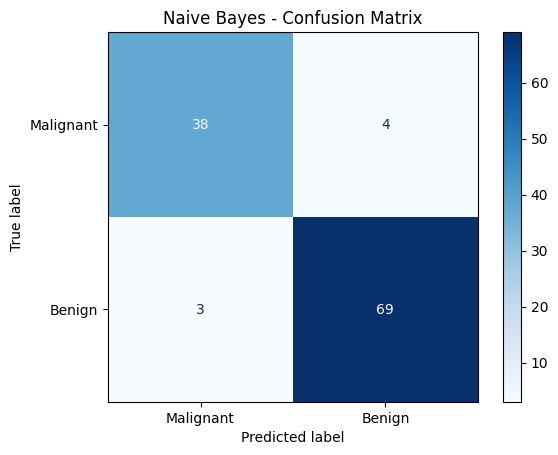

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

display.plot(cmap="Blues")
plt.title("Naive Bayes - Confusion Matrix")
plt.show()

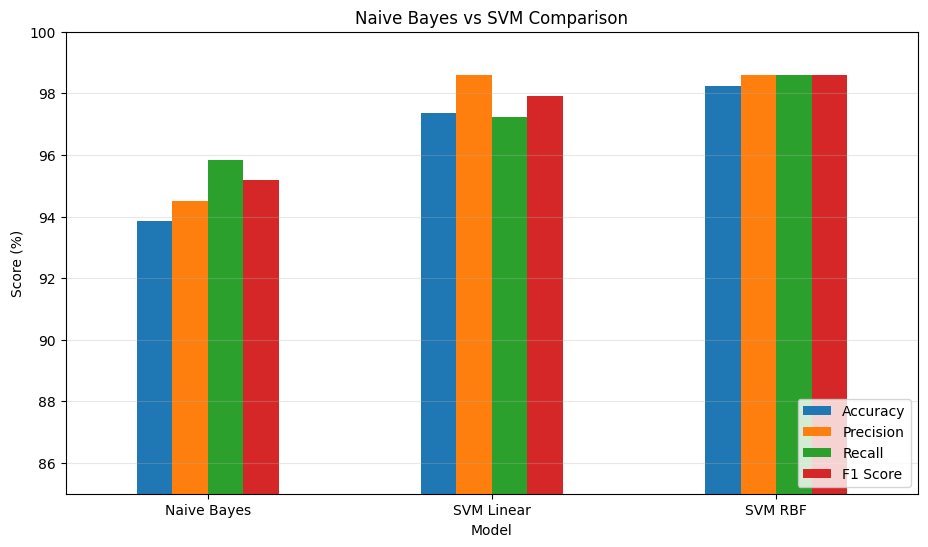

         Model  Accuracy  Precision  Recall  F1 Score
0  Naive Bayes     93.86      94.52   95.83     95.17
1   SVM Linear     97.37      98.59   97.22     97.90
2      SVM RBF     98.25      98.61   98.61     98.61


In [8]:
models = ["Naive Bayes", "SVM Linear", "SVM RBF"]

accuracy_scores = [93.86, 97.37, 98.25]
precision_scores = [94.52, 98.59, 98.61]
recall_scores = [95.83, 97.22, 98.61]
f1_scores = [95.17, 97.90, 98.61]

comparison = pd.DataFrame({
    "Model": models,
    "Accuracy": accuracy_scores,
    "Precision": precision_scores,
    "Recall": recall_scores,
    "F1 Score": f1_scores
})

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Naive Bayes vs SVM Comparison")
plt.ylabel("Score (%)")
plt.ylim(85, 100)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(comparison)